# Linear Regression on Ames Housing

**Objective:** Build and evaluate linear regression models to predict house sale prices with Ames Housing features.

**Dataset used:** `data/AmesHousing.txt`

**Main techniques used:** Exploratory analysis, correlation analysis, simple linear regression, multiple linear regression, RMSE evaluation


In [1]:
import pandas as pd
data = pd.read_csv('data/AmesHousing.txt' ,  delimiter="\t")
train = data[0:1460]
test = data[1460:]
print(train.info())
target = 'SalePrice'
print(len(data))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            1460 non-null   int64  
 1   PID              1460 non-null   int64  
 2   MS SubClass      1460 non-null   int64  
 3   MS Zoning        1460 non-null   object 
 4   Lot Frontage     1211 non-null   float64
 5   Lot Area         1460 non-null   int64  
 6   Street           1460 non-null   object 
 7   Alley            109 non-null    object 
 8   Lot Shape        1460 non-null   object 
 9   Land Contour     1460 non-null   object 
 10  Utilities        1460 non-null   object 
 11  Lot Config       1460 non-null   object 
 12  Land Slope       1460 non-null   object 
 13  Neighborhood     1460 non-null   object 
 14  Condition 1      1460 non-null   object 
 15  Condition 2      1460 non-null   object 
 16  Bldg Type        1460 non-null   object 
 17  House Style   

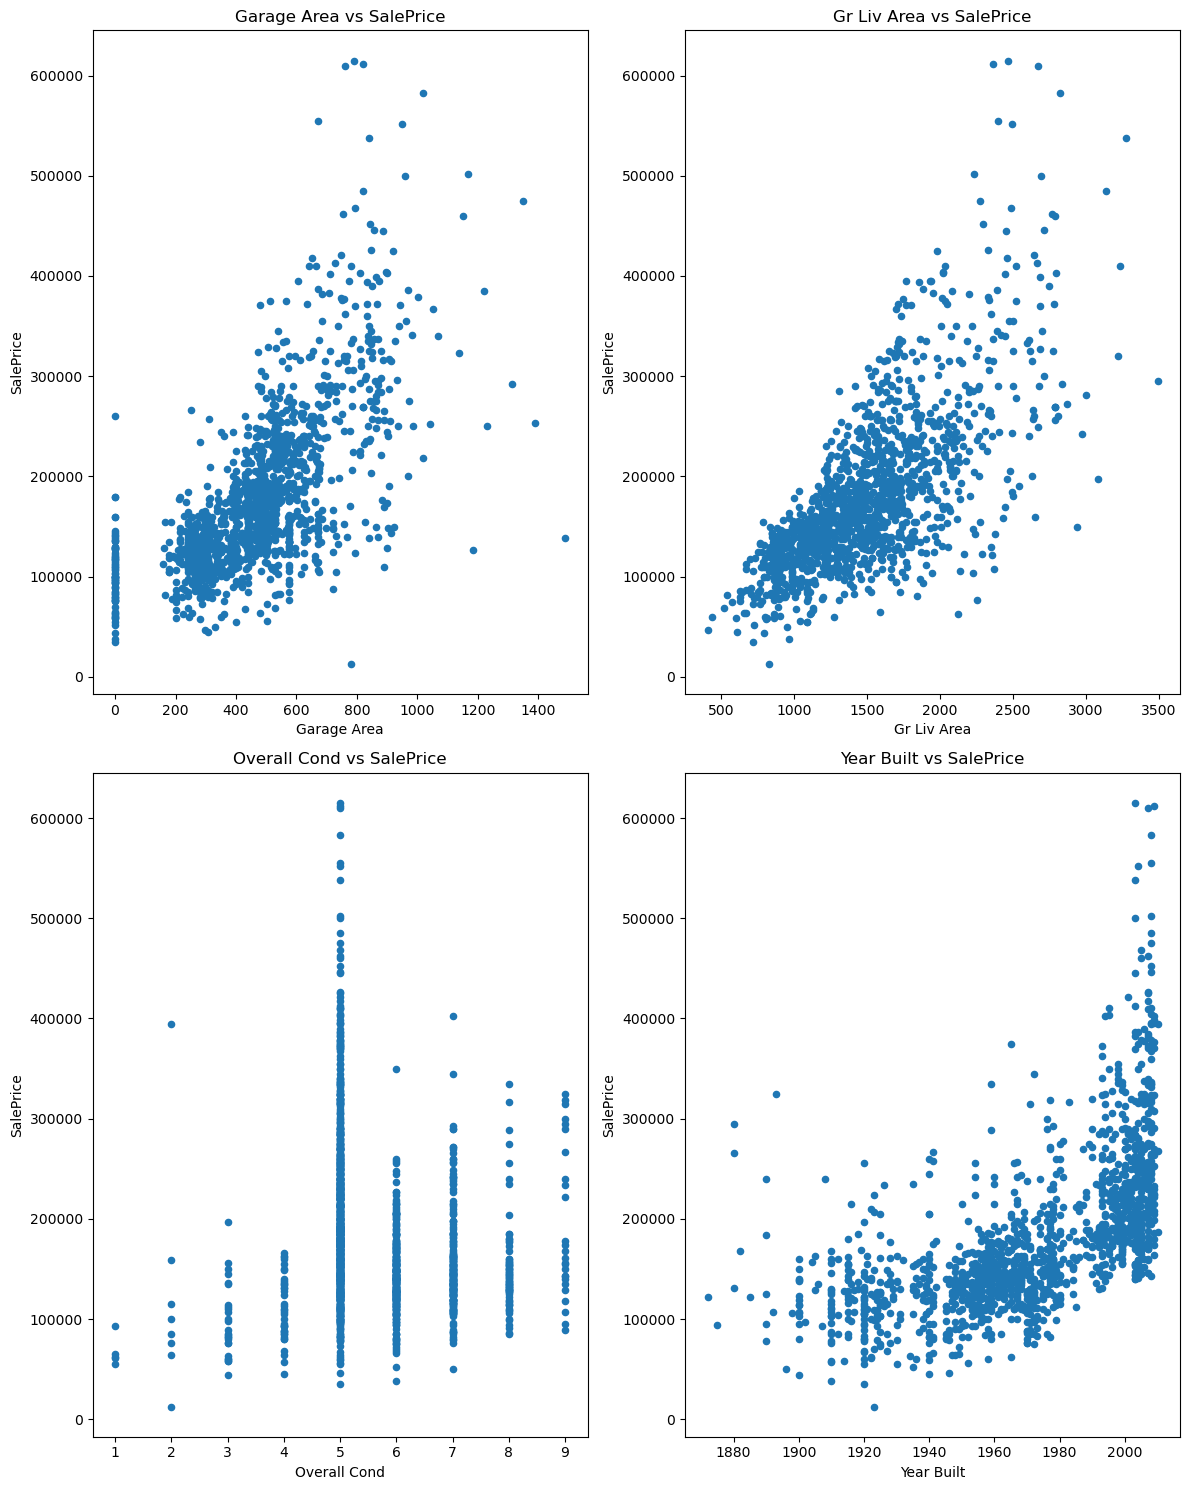

In [8]:
#regression lineaire simplee y =a1*x + b1 
import matplotlib.pyplot as plt

# Créer une figure avec une taille personnalisée
fig = plt.figure(figsize=(12, 15))

# Définir une grille 2x2 (4 sous-graphiques)
ax1 = fig.add_subplot(2, 2, 1)  # 1er graphique en haut à gauche
ax2 = fig.add_subplot(2, 2, 2)  # 2e graphique en haut à droite
ax3 = fig.add_subplot(2, 2, 3)  # 3e graphique en bas à gauche
ax4 = fig.add_subplot(2, 2, 4)  # 4e graphique en bas à droite

# Tracer les scatter plots
train.plot(x='Garage Area', y='SalePrice', ax=ax1, kind='scatter', title='Garage Area vs SalePrice')
train.plot(x='Gr Liv Area', y='SalePrice', ax=ax2, kind='scatter', title='Gr Liv Area vs SalePrice')
train.plot(x='Overall Cond', y='SalePrice', ax=ax3, kind='scatter', title='Overall Cond vs SalePrice')
train.plot(x='Year Built', y='SalePrice', ax=ax4, kind='scatter', title='Year Built vs SalePrice')

# Affichage de la figure
plt.tight_layout()  # Évite les chevauchements
plt.show()

#En résumé
#Ces graphiques sont essentiels pour faire de l'exploration visuelle avant la modélisation, afin de :

#Comprendre les relations

#Choisir les variables explicatives

#Détecter les problèmes potentiels (outliers, non-linéarité)

#Justifier l’utilisation (ou non) d’une régression linéaire


In [10]:
train[['Garage Area' , 'Gr Liv Area' , 'Overall Cond' ,'Year Built', 'SalePrice']].corr()


,Garage Area,Gr Liv Area,Overall Cond,Year Built,SalePrice
Garage Area,1.000000,0.465366,-0.132401,0.507186,0.662397
Gr Liv Area,0.465366,1.000000,-0.133710,0.259462,0.698990
Overall Cond,-0.132401,-0.133710,1.000000,-0.355129,-0.099395
Year Built,0.507186,0.259462,-0.355129,1.000000,0.591436
SalePrice,0.662397,0.698990,-0.099395,0.591436,1.000000


In [20]:
 # 1. Importer les bibliothèques
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 2. Charger les données (à adapter si ton fichier s'appelle autrement)
# Exemple si ton fichier est un CSV :
# train = pd.read_csv('data/AmesHousing.txt')

# Supposons que le DataFrame `train` est déjà chargé

# 3. Séparer les variables explicatives (features) et la cible (target)
X = train[['Gr Liv Area', 'Garage Area', 'Year Built']]  # ou d'autres variables
y = train['SalePrice']

# 4. Diviser en données d'entraînement et de test
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Créer et entraîner le modèle
lr = LinearRegression()
lr.fit(x_train, y_train)

# 6. Afficher les coefficients appris
print("Coefficients :", lr.coef_)
print("Intercept :", lr.intercept_)


Coefficients : [ 77.02887744 102.77439246 862.32086902]
Intercept : -1683332.4864317914


In [21]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(train[['Gr Liv Area']], train['SalePrice'])
print(lr.coef_)
print(lr.intercept_)
a0=lr.coef_
a1=lr.intercept_
#l'equation de notre modele sera y=116.86624683*x1 + 5366.8217006



[116.86624683]
5366.821710056043


In [24]:
from sklearn.linear_model import LinearRegression
import numpy as np 
from sklearn.metrics import mean_squared_error
lr=LinearRegression()
lr.fit(train[['Gr Liv Area']] , train['SalePrice'])
train_predictions = lr.predict(train[['Gr Liv Area']])
test_predictions = lr.predict(test[['Gr Liv Area']])
train_mse=mean_squared_error (train_predictions , train['SalePrice'])
test_mse = mean_squared_error(test_predictions , test['SalePrice'])
train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)
print(train_rmse)
print(test_rmse)


56034.362001412796
57088.25161263909


In [28]:
cols = ['Overall Cond' ,'Gr Liv Area']
lr.fit(train[cols] , train['SalePrice'])
train_predictions =  lr.predict(train[cols])
test_predictions = lr.predict(test[cols])
train_rmse_2 = np.sqrt(mean_squared_error(train_predictions , train['SalePrice']))
test_rmse_2 = np.sqrt(mean_squared_error(test_predictions , test['SalePrice']))
print(train_rmse_2 , test_rmse_2)


56032.398015258674 57066.90779448559


In [34]:
numerical_train = train.select_dtypes(include=['int64' , 'float64'])
numerical_train = numerical_train.drop(['PID' ,'Year Built' , 'Year Remod/Add' , 'Garage Yr Blt' , 
                                        'Mo Sold' , 'Yr Sold'],axis=1)
null_series = numerical_train.isnull().sum()
full_cols_series = null_series[null_series ==0]
print(full_cols_series)


Order              0
MS SubClass        0
Lot Area           0
Overall Qual       0
Overall Cond       0
1st Flr SF         0
2nd Flr SF         0
Low Qual Fin SF    0
Gr Liv Area        0
Full Bath          0
Half Bath          0
Bedroom AbvGr      0
Kitchen AbvGr      0
TotRms AbvGrd      0
Fireplaces         0
Garage Cars        0
Garage Area        0
Wood Deck SF       0
Open Porch SF      0
Enclosed Porch     0
3Ssn Porch         0
Screen Porch       0
Pool Area          0
Misc Val           0
SalePrice          0
dtype: int64


In [36]:
train[['Garage Area' , 'Gr Liv Area' , 'Overall Cond' , 'SalePrice']].corr()



,Garage Area,Gr Liv Area,Overall Cond,SalePrice
Garage Area,1.000000,0.465366,-0.132401,0.662397
Gr Liv Area,0.465366,1.000000,-0.133710,0.698990
Overall Cond,-0.132401,-0.133710,1.000000,-0.099395
SalePrice,0.662397,0.698990,-0.099395,1.000000


In [38]:
len(full_cols_series)


25

In [45]:
train_subset = train [full_cols_series.index]
corrmat = train_subset.corr()
sorted_corrs = corrmat['SalePrice'].abs().sort_values()
print(sorted_corrs)


Misc Val           0.009903
3Ssn Porch         0.038699
Low Qual Fin SF    0.060352
Order              0.068181
MS SubClass        0.088504
Overall Cond       0.099395
Screen Porch       0.100121
Bedroom AbvGr      0.106941
Kitchen AbvGr      0.130843
Pool Area          0.145474
Enclosed Porch     0.165873
2nd Flr SF         0.202352
Half Bath          0.272870
Lot Area           0.274730
Wood Deck SF       0.319104
Open Porch SF      0.344383
TotRms AbvGrd      0.483701
Fireplaces         0.485683
Full Bath          0.518194
1st Flr SF         0.657119
Garage Area        0.662397
Garage Cars        0.663485
Gr Liv Area        0.698990
Overall Qual       0.804562
SalePrice          1.000000
Name: SalePrice, dtype: float64


<Axes: >

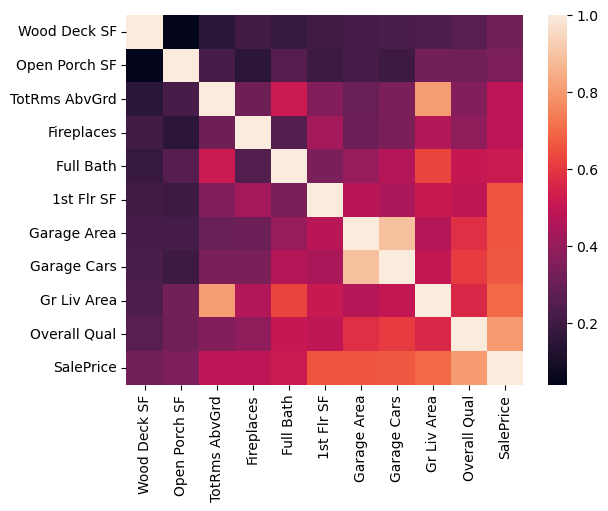

In [57]:
import seaborn as sns
strong_corrs = sorted_corrs[sorted_corrs > 0.3 ]
cormat = train_subset[strong_corrs.index].corr()
sns.heatmap(cormat)


In [ ]:
#anaylse de heatmap
final_corr_cols = strong_corrs.drop(['Garage Cars', 'TotRmsAbvGrd'])
test[final_corr_cols.index]


## Conclusion

**What was done:** Explored Ames Housing features and trained linear regression models with one and multiple predictors.

**What was learned:** Feature correlation and careful variable selection directly affect regression quality.

**Possible improvements:** Add more robust feature engineering, stronger validation, and model comparison with regularized methods.
